In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

In [2]:
df = pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")
print(df.head())
print(df.shape)
print(df.info())

       Product_Name              Brand        Category Usage_Frequency  \
0   Ultra Face Mask     Drunk Elephant           Blush          Weekly   
1    Ultra Lipstick      Laura Mercier  Makeup Remover      Occasional   
2       Ultra Serum     Natasha Denona     Highlighter           Daily   
3      Divine Serum        Ilia Beauty       Face Mask      Occasional   
4  Super Foundation  Charlotte Tilbury     Highlighter      Occasional   

   Price_USD  Rating  Number_of_Reviews Product_Size  Skin_Type Gender_Target  \
0      67.85     1.4                686         30ml  Sensitive        Female   
1     116.43     4.2               5483        250ml        Dry        Unisex   
2      90.84     1.6               5039        100ml  Sensitive          Male   
3      55.17     3.2               6202        250ml     Normal          Male   
4     140.56     1.7                297        100ml       Oily        Female   

  Packaging_Type Main_Ingredient  Cruelty_Free Country_of_Origin  
0

In [3]:
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Column Names:")
print(df.columns.tolist())

Missing Values:
Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64
Duplicate Rows: 0
Column Names:
['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD', 'Rating', 'Number_of_Reviews', 'Product_Size', 'Skin_Type', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin']


In [6]:
target = "Rating"
candidate_features = ["Price_USD","Number_of_Reviews","Product_Type","Category","Skin_Type","Brand","Cruelty_Free"]
features = [col for col in candidate_features if col in df.columns]
print("Selected features:", features)
print("Target variable:", target)

Selected features: ['Price_USD', 'Number_of_Reviews', 'Category', 'Skin_Type', 'Brand', 'Cruelty_Free']
Target variable: Rating


In [7]:
X = df[features].copy()
y = pd.to_numeric(df[target], errors="coerce")
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (15000, 6)
Target shape: (15000,)


In [9]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["str", "category", "bool"]).columns.tolist()
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Price_USD', 'Number_of_Reviews']
Categorical features: ['Category', 'Skin_Type', 'Brand', 'Cruelty_Free']


In [10]:
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numerical_features),("cat", categorical_transformer, categorical_features)])

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (12000, 6)
Testing Data: (3000, 6)


In [12]:
linear_model = Pipeline(steps=[("preprocessor", preprocessor),("model", LinearRegression())])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

In [13]:
decision_tree_model = Pipeline(steps=[("preprocessor", preprocessor),("model", DecisionTreeRegressor(max_depth=5,random_state=42))])
decision_tree_model.fit(X_train, y_train)
dt_predictions = decision_tree_model.predict(X_test)

In [14]:
random_forest_model = Pipeline(steps=[("preprocessor", preprocessor),("model", RandomForestRegressor(n_estimators=100,max_depth=10,random_state=42))])
random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)

In [15]:
def evaluate_model(y_test, predictions, model_name):
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)
    return {"Model": model_name,"MAE": mae,"MSE": mse,"RMSE": rmse,"R2 Score": r2}

In [16]:
results = []
results.append(evaluate_model(y_test,linear_predictions,"Linear Regression"))
results.append(evaluate_model(y_test,dt_predictions,"Decision Tree"))
results.append(evaluate_model(y_test,rf_predictions,"Random Forest"))
results_df = pd.DataFrame(results)
print(results_df)

               Model       MAE       MSE      RMSE  R2 Score
0  Linear Regression  1.024362  1.381188  1.175240 -0.005850
1      Decision Tree  1.027338  1.398230  1.182468 -0.018261
2      Random Forest  1.023286  1.380066  1.174762 -0.005034


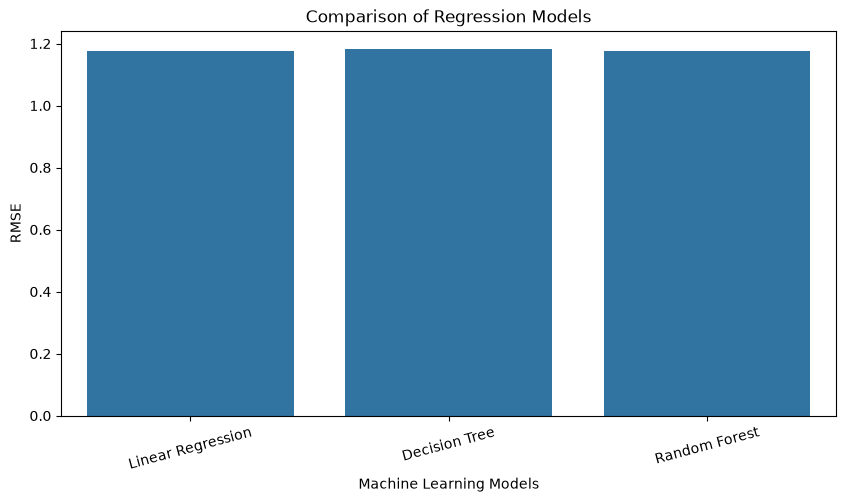

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df,x="Model",y="RMSE")
plt.title("Comparison of Regression Models")
plt.ylabel("RMSE")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15)
plt.show()

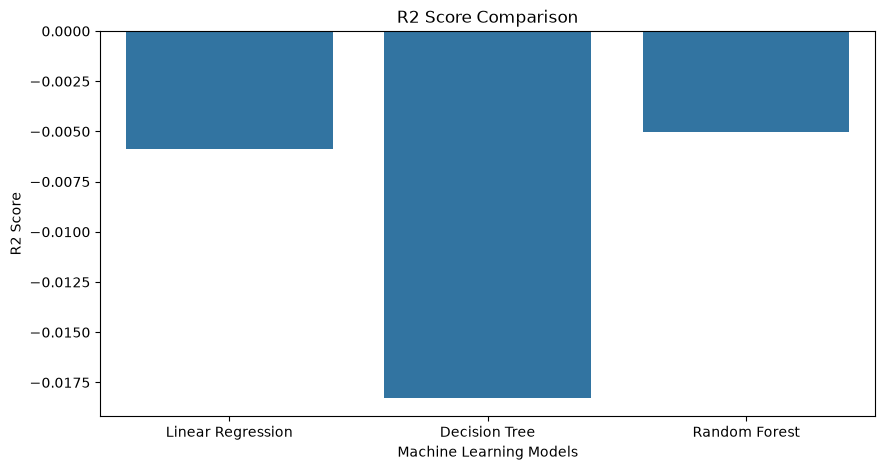

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df,x="Model",y="R2 Score")
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")
plt.show()

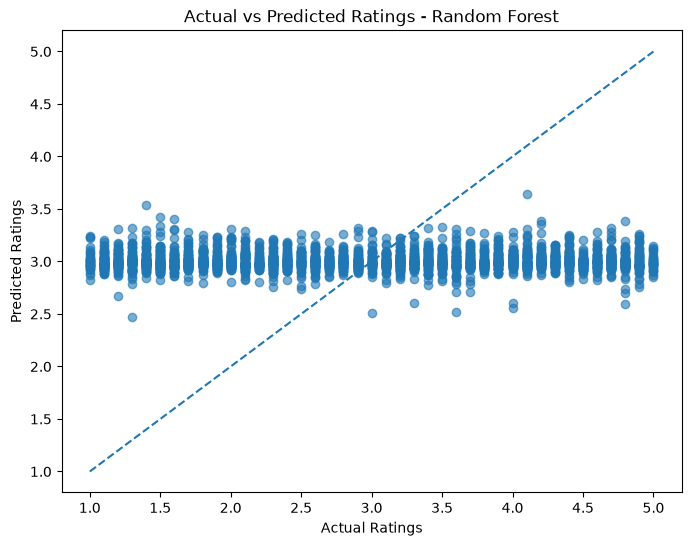

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test,rf_predictions,alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],linestyle="--")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.title("Actual vs Predicted Ratings - Random Forest")
plt.show()

In [20]:
rf = random_forest_model.named_steps["model"]
feature_names = (random_forest_model.named_steps["preprocessor"].get_feature_names_out())
importance_df = pd.DataFrame({"Feature": feature_names,"Importance": rf.feature_importances_})
importance_df = importance_df.sort_values(by="Importance",ascending=False)
print(importance_df.head(10))

                       Feature  Importance
0               num__Price_USD    0.254290
1       num__Number_of_Reviews    0.244222
28       cat__Skin_Type_Normal    0.019654
29         cat__Skin_Type_Oily    0.013583
30    cat__Skin_Type_Sensitive    0.013138
26  cat__Skin_Type_Combination    0.012693
27          cat__Skin_Type_Dry    0.012185
55      cat__Brand_Milk Makeup    0.012042
72      cat__Cruelty_Free_True    0.011174
8        cat__Category_Contour    0.010731


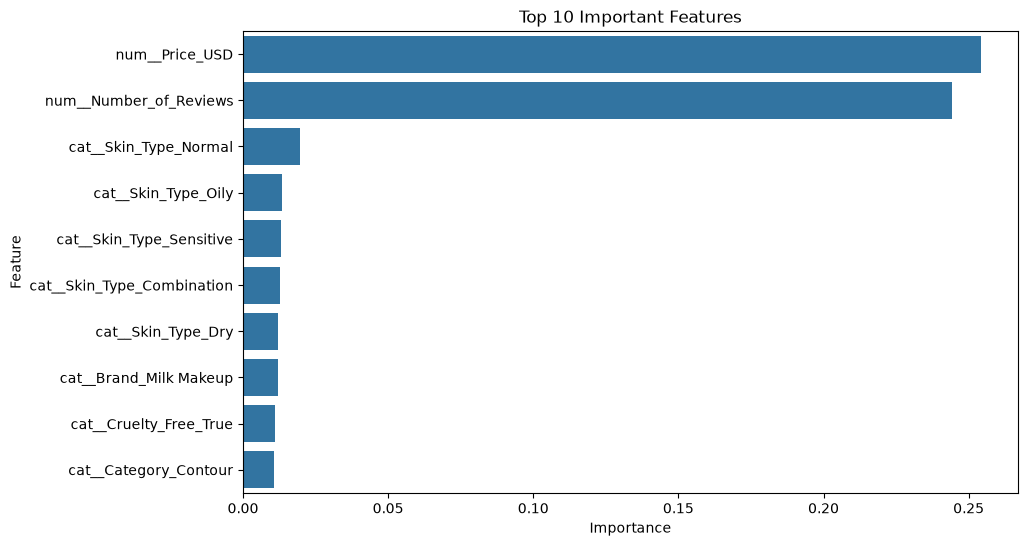

In [21]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10),x="Importance",y="Feature")
plt.title("Top 10 Important Features")
plt.show()

In [24]:
models = {"Linear Regression": linear_model,"Decision Tree": decision_tree_model,"Random Forest": random_forest_model}
for name, model in models.items():
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)
    print("\n", name)
    print("Training R2:", train_score)
    print("Testing R2:", test_score)


 Linear Regression
Training R2: 0.0061739240441234244
Testing R2: -0.005850450087203196

 Decision Tree
Training R2: 0.01412623257536938
Testing R2: -0.01826130938466819

 Random Forest
Training R2: 0.09902555276609637
Testing R2: -0.0050335508132817175


In [25]:
for name, model in models.items():
    scores = cross_val_score(model,X,y,cv=5,scoring="r2")
    print("\n", name)
    print("Cross Validation Scores:", scores)
    print("Average R2 Score:", scores.mean())


 Linear Regression
Cross Validation Scores: [-0.01131878 -0.0093054   0.00035804 -0.00523122 -0.00993264]
Average R2 Score: -0.007086002223681387

 Decision Tree
Cross Validation Scores: [-0.01342078 -0.01284365 -0.0127345  -0.01870386 -0.01493498]
Average R2 Score: -0.014527553057930298

 Random Forest
Cross Validation Scores: [-0.00586146 -0.00462949 -0.00160181 -0.00277915 -0.00805213]
Average R2 Score: -0.004584808044582012


In [26]:
new_product = pd.DataFrame([{col: X[col].mode()[0]
    if col in categorical_features
    else X[col].median()
    for col in features}])
predicted_rating = random_forest_model.predict(new_product)
print("Predicted Product Rating:", predicted_rating[0])

Predicted Product Rating: 3.023156568734897
